<a href="https://colab.research.google.com/github/jalmendral/BA305-A1-TeamA2/blob/main/cuisine_PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PCA project: Do nutritional profiles separate national cuisines?**

dataset: `recipes_clean.csv` (Allrecipes)

**Question:** Do nutritional profiles separate national cuisines, or do many cuisines collapse into a few nutritional profiles?

**Plan:** run PCA on the nutrition variables only (cuisine is *not* an input), then check where each cuisine lands in the component space.

In [ ]:
# Load the libraries this project uses, and draw plots inside the notebook.
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px                          # interactive plots (pre-installed on Colab)
from sklearn.preprocessing import StandardScaler     # does the scaling for us
from sklearn.decomposition import PCA                # does the PCA for us

## **Task 1:** Data cleaning (without scaling yet)

PCA only works on metric variables, so we keep the four nutrition columns and remove empty entries. We also need recipes that carry a cuisine tag (`country`), since that is what we compare at the end.

In [ ]:
# load the data and review
# in Colab: upload recipes_clean.csv when prompted
try:
    from google.colab import files
    uploaded = files.upload()
    recipes_df = pd.read_csv(list(uploaded.keys())[0])
except ImportError:
    recipes_df = pd.read_csv('recipes_clean.csv')
recipes_df.head()

Saving recipes_clean.csv to recipes_clean.csv


,name,url,author,date_published,ingredients,calories,fat,carbs,protein,avg_rating,...,cook_time,total_time,servings,country,has_cuisine,year,nutrition_flag,time_flag,rating_missing,nutrition_missing
0,Chewy Whole Wheat Peanut Butter Brownies,https://www.allrecipes.com/recipe/140717/chewy...,DMOMMY,2020-06-18,"⅓ cup margarine, softened, ⅔ cup white sugar, ...",222.0,13.0,24.0,6.0,4.4,...,35.0,55.0,16.0,NaN,False,2020,False,False,False,False
1,Pumpkin Pie Eggnog,https://www.allrecipes.com/recipe/269204/pumpk...,Bobbie Susan,2022-09-26,"12 egg yolks, 2 cups heavy whipping cream, ½ ...",477.0,31.0,43.0,8.0,5.0,...,5.0,495.0,8.0,NaN,False,2022,False,False,False,False
2,Eggs Poached in Tomato Sauce,https://www.allrecipes.com/recipe/238054/eggs-...,Bren,2018-06-08,"2 tablespoons olive oil, or to taste, ½ onion...",354.0,18.0,32.0,20.0,4.8,...,75.0,85.0,4.0,NaN,False,2018,False,False,False,False
3,Minestrone Casserole,https://www.allrecipes.com/minestrone-casserol...,Sarah Brekke,2025-03-03,4 cups dried mafalda pasta (mini lasagna noodl...,356.0,9.0,53.0,19.0,4.3,...,40.0,60.0,8.0,NaN,False,2025,False,False,False,False
4,Yummy Stuffed Peppers,https://www.allrecipes.com/recipe/241937/yummy...,Procrastigirl,2024-12-11,"4 green bell peppers, halved lengthwise and se...",366.0,22.0,23.0,19.0,4.7,...,95.0,125.0,8.0,NaN,False,2024,False,False,False,False


In [ ]:
# shape of dataframe
recipes_df.shape

(15589, 23)

In [ ]:
# concise summary containing variable types
recipes_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15589 entries, 0 to 15588
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   name               15589 non-null  object 
 1   url                15589 non-null  object 
 2   author             15589 non-null  object 
 3   date_published     15589 non-null  object 
 4   ingredients        15579 non-null  object 
 5   calories           15351 non-null  float64
 6   fat                15189 non-null  float64
 7   carbs              15345 non-null  float64
 8   protein            15300 non-null  float64
 9   avg_rating         14559 non-null  float64
 10  total_ratings      14559 non-null  float64
 11  reviews            14451 non-null  float64
 12  prep_time          15183 non-null  float64
 13  cook_time          15183 non-null  float64
 14  total_time         15183 non-null  float64
 15  servings           15566 non-null  float64
 16  country            221

In [ ]:
# the columns PCA will use (measurements) and the label we will group by afterwards
nutrition = ['calories', 'fat', 'carbs', 'protein']
label = 'country'

# drop missing values on the FULL table, so the name and country stay lined up with the rows we keep
recipes_clean = recipes_df.dropna(subset=nutrition + [label])

# drop cuisines with too few recipes to give a stable average
counts = recipes_clean[label].value_counts()
recipes_clean = recipes_clean[recipes_clean[label].isin(counts[counts >= 30].index)]

# reset the index after dropping rows
recipes_clean = recipes_clean.reset_index(drop=True)
print(recipes_clean.shape, '|', recipes_clean[label].nunique(), 'cuisines')

(1867, 23) | 34 cuisines


In [ ]:
# keep only the metric columns for the PCA
recipes_mdf = recipes_clean[nutrition]
recipes_mdf.head()

,calories,fat,carbs,protein
0,1262.0,85.0,56.0,66.0
1,581.0,34.0,64.0,10.0
2,241.0,13.0,28.0,4.0
3,861.0,34.0,78.0,57.0
4,344.0,22.0,35.0,4.0


In [ ]:
# how many recipes per cuisine made it through?
recipes_clean[label].value_counts()

,count
country,
Canadian,66
Indian,65
Filipino,65
Russian,65
Chinese,65
French,65
Brazilian,64
Soul Food,63
Cajun and Creole,63


**Note.** The file has 15,589 recipes, but only recipes with a cuisine tag and complete nutrition can be used. That leaves about 1,900 recipes in 34 cuisines. Mention in the write-up that tagged recipes may not represent the whole site.

## **Task 2:** Check the correlations between the columns

In [ ]:
# correlation table for the nutrition variables
corr_mat = recipes_mdf.corr()
corr_mat

,calories,fat,carbs,protein
calories,1.000000,0.863626,0.593984,0.697361
fat,0.863626,1.000000,0.197231,0.551894
carbs,0.593984,0.197231,1.000000,0.138894
protein,0.697361,0.551894,0.138894,1.000000


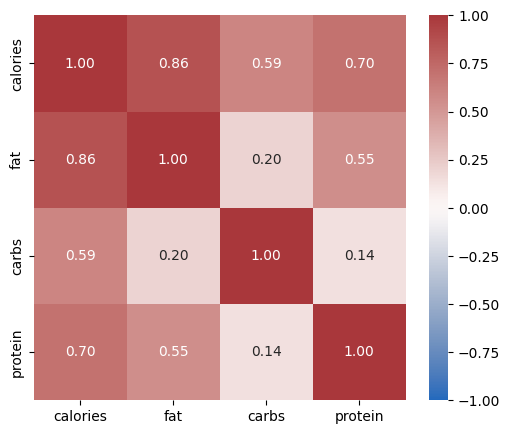

In [ ]:
# heatmap with a diverging colormap: blue = negative, white = zero, red = positive
plt.figure(figsize=(6,5))
sns.heatmap(corr_mat, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap='vlag');

Calories are strongly correlated with the other three because calories are *computed* from them (about 9×fat + 4×carbs + 4×protein). Expect the last component to carry almost no variance for that reason.

## **Task 3:** Scale the data and run PCA

In [ ]:
# min, max, mean and standard deviation for every variable, most spread out first
spread = recipes_mdf.agg(['min', 'max', 'mean', 'std']).T.sort_values('std', ascending=False)
print('most variable column is', round(spread['std'].max() / spread['std'].min()),
      'times more spread out than the least')
spread.round(1)

most variable column is 15 times more spread out than the least


,min,max,mean,std
calories,3.0,1793.0,360.5,230.0
carbs,1.0,181.0,31.9,25.6
fat,0.0,151.0,18.6,16.1
protein,0.0,95.0,16.9,15.8


Calories are measured on a much bigger scale than grams of fat or protein. Unscaled, calories would dominate PC1 because of its units, so we standardize: one variable, one vote.

In [ ]:
# Standardization (0 mean, unit variance) with sklearn's StandardScaler
scaler = StandardScaler()
scaled_df = pd.DataFrame(scaler.fit_transform(recipes_mdf), columns=recipes_mdf.columns)
scaled_df.head()

,calories,fat,carbs,protein
0,3.920730,4.121442,0.940751,3.104881
1,0.959043,0.954630,1.253365,-0.436200
2,-0.519626,-0.349351,-0.153398,-0.815602
3,2.176770,0.954630,1.800440,2.535779
4,-0.071676,0.209498,0.120140,-0.815602


In [ ]:
# check that the scaler worked: mean 0, std 1
scaled_df.agg(['mean', 'std']).round(3)

,calories,fat,carbs,protein
mean,-0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0


In [ ]:
# PCA after scaling -- with 4 variables there are at most 4 components
pcs = PCA(n_components=4)
scores = pcs.fit_transform(scaled_df)

pc_names = ['PC' + str(i+1) for i in range(pcs.n_components_)]
scores_df = pd.DataFrame(scores, columns=pc_names)

eig = pcs.explained_variance_

summary_df = pd.DataFrame({
    'Eigenvalue': eig,
    '% of variance': pcs.explained_variance_ratio_ * 100,
    'Cumulative %': np.cumsum(pcs.explained_variance_ratio_) * 100
}, index=pc_names)
summary_df.round(3)

,Eigenvalue,% of variance,Cumulative %
PC1,2.614,65.305,65.305
PC2,0.931,23.260,88.565
PC3,0.454,11.353,99.918
PC4,0.003,0.082,100.000


### From **weights** to the **component matrix**

In [ ]:
# weights: components_ has components on the rows, so transpose
weights_df = pd.DataFrame(pcs.components_.T, index=recipes_mdf.columns, columns=pc_names)
weights_df.round(3)

,PC1,PC2,PC3,PC4
calories,0.614,0.085,-0.105,0.777
fat,0.533,-0.274,-0.642,-0.478
carbs,0.333,0.867,0.157,-0.336
protein,0.477,-0.408,0.743,-0.232


In [ ]:
# component matrix: correlation of each original variable with each component
loadings_df = pd.concat([scores_df, scaled_df], axis=1).corr().loc[recipes_mdf.columns, pc_names]
loadings_df.round(2)

,PC1,PC2,PC3,PC4
calories,0.99,0.08,-0.07,0.04
fat,0.86,-0.26,-0.43,-0.03
carbs,0.54,0.84,0.11,-0.02
protein,0.77,-0.39,0.50,-0.01


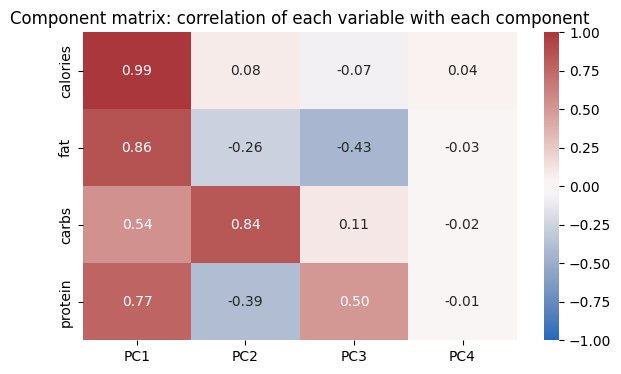

In [ ]:
plt.figure(figsize=(7,4))
sns.heatmap(loadings_df, annot=True, fmt=".2f", vmin=-1, vmax=1, cmap='vlag')
plt.title('Component matrix: correlation of each variable with each component');

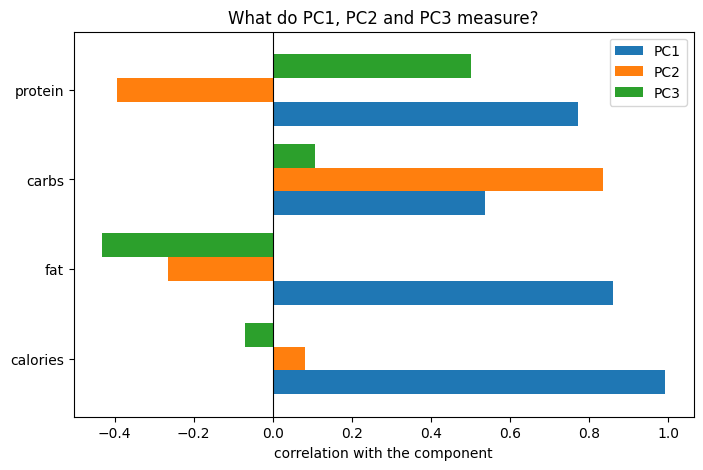

In [ ]:
# one component at a time, as a bar chart
loadings_df[['PC1','PC2','PC3']].plot.barh(figsize=(8,5), width=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel('correlation with the component')
plt.title('What do PC1, PC2 and PC3 measure?');

**Interpretation (fill in):** in plain language, what does each component measure?
- PC1: *all four variables load positively → ...*
- PC2: *...*
- PC3: *...*

## **Task 4:** How many components do we need?

In [ ]:
print(summary_df['Eigenvalue'].round(2).to_string())

PC1    2.61
PC2    0.93
PC3    0.45
PC4    0.00


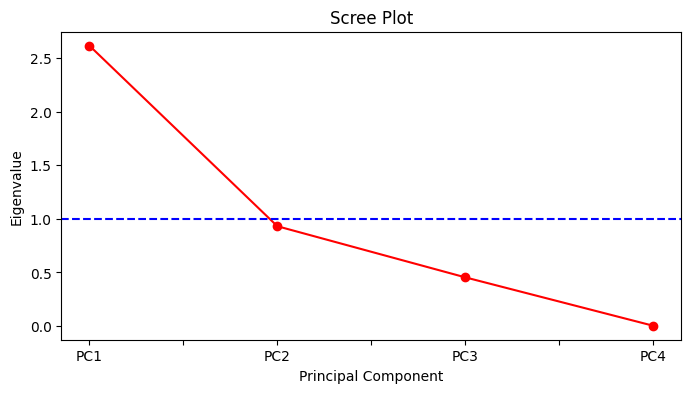

In [ ]:
# scree plot of eigenvalues, with the latent root (Kaiser) cut-off at 1
ax = summary_df['Eigenvalue'].plot(marker='o', color='red', figsize=(8,4))
ax.axhline(y=1, color='b', linestyle='--')
ax.set_title('Scree Plot')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Eigenvalue');

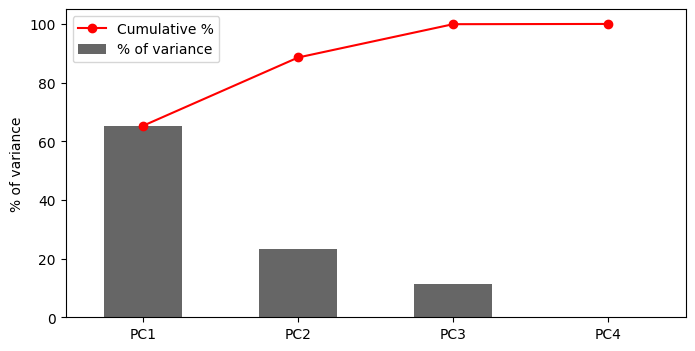

In [ ]:
# the same story as variance explained
ax = summary_df['% of variance'].plot.bar(figsize=(8,4), color='0.4')
summary_df['Cumulative %'].plot(marker='o', color='red', ax=ax)
ax.set_ylabel('% of variance')
ax.legend(['Cumulative %', '% of variance']);

**Note.** With only 4 variables, the Kaiser rule is strict. Look at how close PC2's eigenvalue is to 1 and at the cumulative %. Below we keep **3 components** (PC4 is ~0 because calories are computed from the other three) and plot the first two.

## **Task 5:** Answer the research question: where do the cuisines land?

Merge the component scores back with the cleaned table (the rows still line up because we dropped missing values *before* splitting off the labels).

In [ ]:
# keep the first 3 components and merge them with the cleaned dataframe
recipes_aug = pd.concat([recipes_clean, scores_df[['PC1','PC2','PC3']].round(3)], axis=1)
recipes_aug[['name', label, 'PC1', 'PC2', 'PC3']].head()

,name,country,PC1,PC2,PC3
0,Chef John's Buttermilk Fried Chicken,Soul Food,6.400,-1.247,-0.602
1,Polish Poppy Seed Cake,Polish,1.307,1.084,-0.841
2,Haroset for Passover,Jewish,-0.946,0.251,-0.351
3,Chicken Marsala Fettuccine,Italian,3.655,0.450,1.326
4,Apple Walnut Canadian Butter Tarts,Canadian,-0.281,0.373,-0.714


In [ ]:
# every recipe on the first two components, colored by cuisine
# hover over a dot to see the recipe
px.scatter(recipes_aug, x='PC1', y='PC2', color=label, hover_name='name', opacity=0.6,
           title='Recipes on their first two principal components, colored by cuisine')

With 34 colors this is hard to read on its own. Double-click a cuisine in the legend to show just that one, then single-click others to add them. Overlapping clouds = cuisines that share a nutritional profile.

In [ ]:
# average position of each cuisine on the components
country_means = recipes_aug.groupby(label)[['PC1','PC2','PC3']].mean()
country_means['n recipes'] = recipes_aug[label].value_counts()
country_means.round(2).sort_values('PC1')

,PC1,PC2,PC3,n recipes
country,,,,
Danish,-0.85,0.14,-0.17,33
Australian and New Zealander,-0.71,0.54,-0.29,63
Swedish,-0.65,0.17,-0.25,30
Lebanese,-0.63,0.02,-0.01,49
Amish and Mennonite,-0.59,0.44,-0.06,61
Scandinavian,-0.55,0.01,-0.29,33
Jewish,-0.46,0.17,-0.06,61
Brazilian,-0.43,0.36,-0.02,64
Russian,-0.36,-0.00,-0.12,65


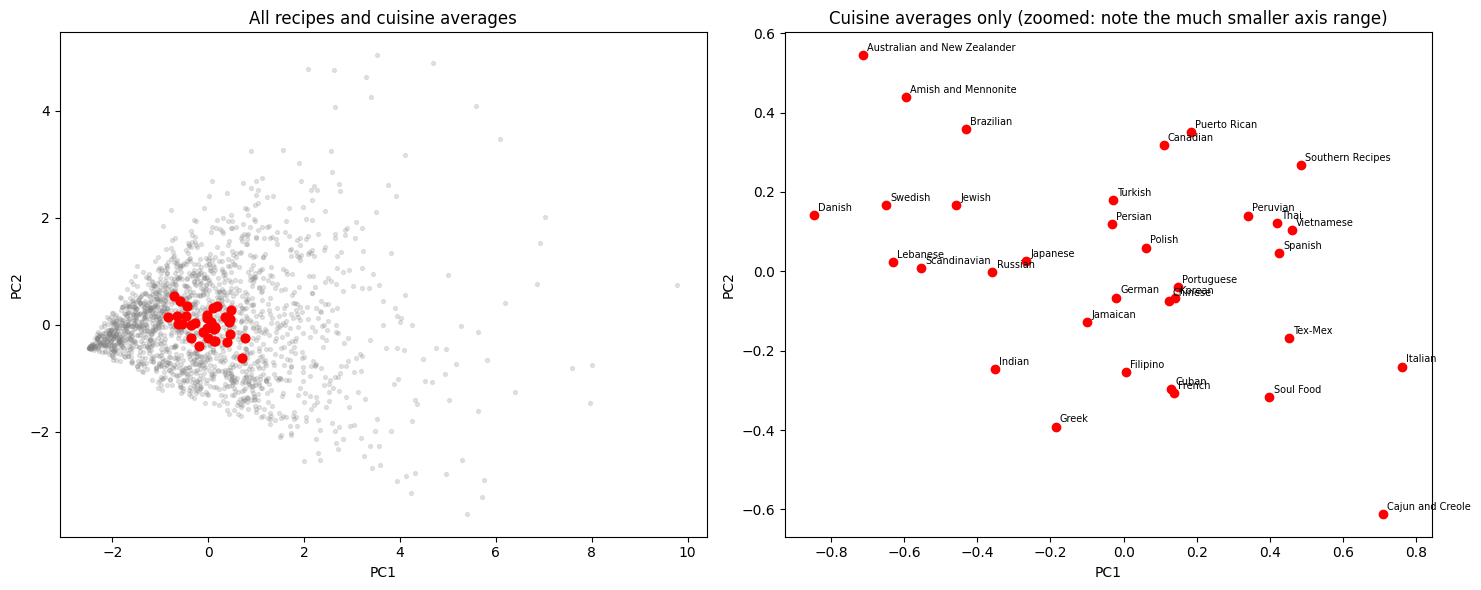

In [ ]:
# left: all recipes (gray) with cuisine averages (red) on the SAME scale
# right: zoomed in on the averages only
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

axes[0].scatter(recipes_aug['PC1'], recipes_aug['PC2'], s=8, alpha=0.2, color='gray')
axes[0].scatter(country_means['PC1'], country_means['PC2'], s=40, color='red')
axes[0].set_title('All recipes and cuisine averages')

axes[1].scatter(country_means['PC1'], country_means['PC2'], color='red')
for c, r in country_means.iterrows():
    axes[1].annotate(c, (r['PC1'], r['PC2']), fontsize=7, xytext=(3, 3), textcoords='offset points')
axes[1].set_title('Cuisine averages only (zoomed: note the much smaller axis range)')

for ax in axes:
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
plt.tight_layout()
plt.show()

### How much of each component's variation is *between* cuisines?

Share of variation explained by cuisine = variation of the cuisine averages around the overall mean ÷ total variation. Near 0 → cuisines overlap (collapse); near 1 → cuisines separate.

In [ ]:
share = {}
for pc in ['PC1', 'PC2', 'PC3']:
    g = recipes_aug.groupby(label)[pc]
    between = (g.count() * (g.mean() - recipes_aug[pc].mean())**2).sum()
    total = ((recipes_aug[pc] - recipes_aug[pc].mean())**2).sum()
    share[pc] = between / total
pd.Series(share, name='share explained by cuisine').round(3)

,share explained by cuisine
PC1,0.064
PC2,0.074
PC3,0.058


In [ ]:
# what would we get by chance? shuffle the cuisine labels and recompute, 500 times
rng = np.random.default_rng(0)
for pc in ['PC1', 'PC2', 'PC3']:
    y = recipes_aug[pc]
    total = ((y - y.mean())**2).sum()
    null = []
    for _ in range(500):
        g = y.groupby(rng.permutation(recipes_aug[label].values))
        null.append((g.count() * (g.mean() - y.mean())**2).sum() / total)
    print(f"{pc}: observed {share[pc]:.3f} | chance level {np.mean(null):.3f} "
          f"| p = {(np.array(null) >= share[pc]).mean():.3f}")

PC1: observed 0.064 | chance level 0.018 | p = 0.000
PC2: observed 0.074 | chance level 0.018 | p = 0.000
PC3: observed 0.058 | chance level 0.018 | p = 0.000


In [ ]:
# Map each cuisine to a broader culinary region (teammate's mapping)
CUISINE_REGION = {
    'Chinese': 'East Asian', 'Japanese': 'East Asian', 'Korean': 'East Asian',
    'Filipino': 'Southeast Asian', 'Thai': 'Southeast Asian',
    'Vietnamese': 'Southeast Asian', 'Malaysian': 'Southeast Asian',
    'Indonesian': 'Southeast Asian',
    'Indian': 'South Asian', 'Pakistani': 'South Asian', 'Bangladeshi': 'South Asian',
    'Lebanese': 'Middle Eastern', 'Persian': 'Middle Eastern',
    'Turkish': 'Middle Eastern', 'Israeli': 'Middle Eastern',
    'Brazilian': 'Latin American', 'Cuban': 'Latin American',
    'Puerto Rican': 'Latin American', 'Jamaican': 'Latin American',
    'Peruvian': 'Latin American', 'Argentinian': 'Latin American',
    'Chilean': 'Latin American', 'Colombian': 'Latin American',
    'Soul Food': 'US Regional', 'Cajun and Creole': 'US Regional',
    'Southern Recipes': 'US Regional', 'Amish and Mennonite': 'US Regional',
    'Tex-Mex': 'US Regional',
    'German': 'Central European', 'Austrian': 'Central European',
    'Swiss': 'Central European', 'Dutch': 'Central European',
    'Belgian': 'Central European',
    'Russian': 'Eastern European', 'Polish': 'Eastern European',
    'Scandinavian': 'Nordic', 'Danish': 'Nordic', 'Swedish': 'Nordic',
    'Norwegian': 'Nordic', 'Finnish': 'Nordic',
    'Greek': 'Mediterranean', 'Spanish': 'Mediterranean',
    'Portuguese': 'Mediterranean',
    'Italian': 'Italian', 'French': 'French', 'Jewish': 'Jewish',
    'Canadian': 'Anglo', 'Australian and New Zealander': 'Anglo',
    'South African': 'South African',
}

# add a region column to the recipes (label = 'country')
recipes_aug['region'] = recipes_aug[label].map(CUISINE_REGION)

# anything unmapped would silently vanish from every chart below
print("unmapped:", recipes_aug.loc[recipes_aug['region'].isna(), label].unique())

# how many cuisines and recipes ended up in each region?
recipes_aug.groupby('region').agg(cuisines=(label, 'nunique'),
                                  recipes=(label, 'size')).sort_values('recipes')

unmapped: []


,cuisines,recipes
region,,
Central European,1,60
Italian,1,61
Jewish,1,61
French,1,65
South Asian,1,65
Nordic,3,96
Eastern European,2,126
Middle Eastern,3,126
Anglo,2,129


In [ ]:
# map each cuisine to a broader culinary region (teammate's mapping)
recipes_aug['region'] = recipes_aug['country'].map(CUISINE_REGION)
# anything unmapped would silently vanish from every chart below
print("unmapped:", recipes_aug.loc[recipes_aug['region'].isna(), 'country'].unique())

# share of each component's variation explained by country vs. region
rows = {}
for pc in ['PC1', 'PC2', 'PC3']:
    y = recipes_aug[pc]
    total = ((y - y.mean())**2).sum()
    rows[pc] = {}
    for grp in ['country', 'region']:
        g = y.groupby(recipes_aug[grp])
        rows[pc][grp] = (g.count() * (g.mean() - y.mean())**2).sum() / total
pd.DataFrame(rows).T.round(3)

unmapped: []


,country,region
PC1,0.064,0.034
PC2,0.074,0.029
PC3,0.058,0.032


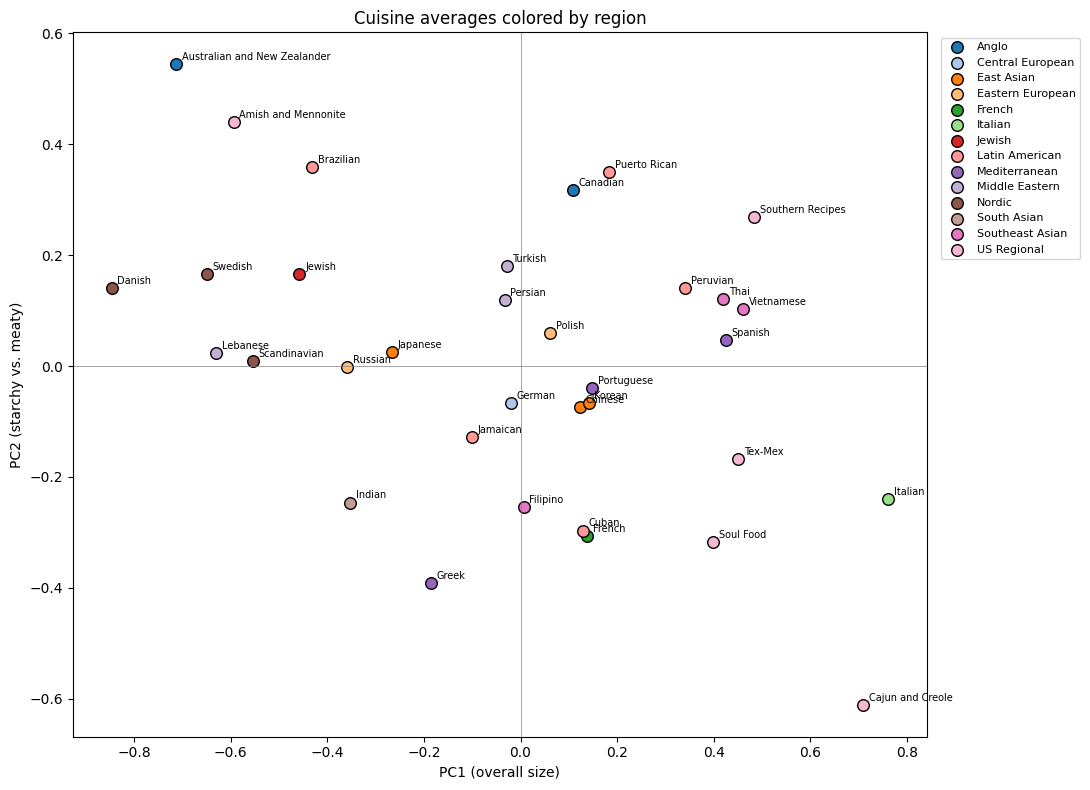

In [ ]:
# cuisine averages, colored by region
# if regions were nutritionally meaningful, same-colored dots would cluster together
country_region = recipes_aug.groupby(label)['region'].first()
country_means['region'] = country_region

plt.figure(figsize=(11, 8))
palette = dict(zip(sorted(country_means['region'].unique()),
                   sns.color_palette('tab20', country_means['region'].nunique())))
for reg, g in country_means.groupby('region'):
    plt.scatter(g['PC1'], g['PC2'], s=70, color=palette[reg], label=reg, edgecolor='black')
for c, r in country_means.iterrows():
    plt.annotate(c, (r['PC1'], r['PC2']), fontsize=7, xytext=(4, 3), textcoords='offset points')
plt.axhline(0, color='gray', lw=0.5); plt.axvline(0, color='gray', lw=0.5)
plt.xlabel('PC1 (overall size)'); plt.ylabel('PC2 (starchy vs. meaty)')
plt.title('Cuisine averages colored by region')
plt.legend(fontsize=8, bbox_to_anchor=(1.01, 1), loc='upper left')
plt.tight_layout();

### Which cuisines group together?

Cluster the cuisine averages: cuisines that join early have similar nutritional profiles.

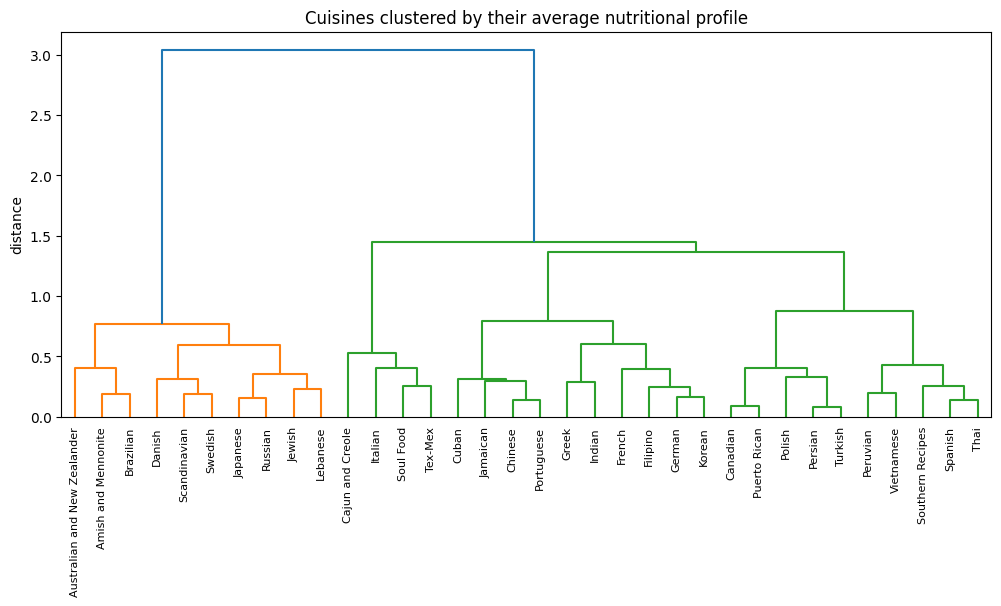

In [ ]:
# hierarchical clustering of the cuisine averages on the 3 kept components
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(country_means[['PC1','PC2','PC3']], method='ward')
plt.figure(figsize=(12, 5))
dendrogram(Z, labels=country_means.index.tolist(), leaf_rotation=90, leaf_font_size=8)
plt.title('Cuisines clustered by their average nutritional profile')
plt.ylabel('distance');

### A non-linear check: t-SNE

Same caution as in class: t-SNE axes have no meaning, and distances between groups aren't meaningful. If cuisines don't form separate islands here either, that supports the "collapse" answer.

In [ ]:
from sklearn.manifold import TSNE

recipes_aug[['t1', 't2']] = TSNE(n_components=2, perplexity=30,
                                 random_state=0).fit_transform(scaled_df)

px.scatter(recipes_aug, x='t1', y='t2', color=label, hover_name='name', opacity=0.6,
           labels={'t1': 'dimension 1 (no units)', 't2': 'dimension 2 (no units)'},
           title='The same recipes, embedded by t-SNE')

---
## **Conclusion (fill in)**

- How many components summarize the nutrition data, and what do they mean?
- How much of the variation is between cuisines vs. within cuisines? Is it more than chance?
- Which cuisines group together in the dendrogram?
- **Answer:** separate, or collapse into a few profiles?

**Limitations to mention:** only 4 nutrition variables; only tagged recipes; cuisine tags are applied to different mixes of dishes (some cuisines are tagged mostly on desserts, others mostly on mains), so part of any difference between cuisine averages may reflect dish mix rather than cuisine.